**Assignment no. 2:**

**Feature Engineering**


Scrap and create your own dataset, do feature engineering on dataset (encoding), and use data visualization.


 Name: Shruti Siddheshwar Thorat

 PRN: 202401040053

 Roll No:16

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from google.colab import files

uploaded = files.upload()
file_name = next(iter(uploaded))

df = pd.read_csv(file_name)

print("Dataset loaded successfully!")
print("Original dataset shape:", df.shape)
display(df.head())

Saving book_feature_dataset (3).csv to book_feature_dataset (3).csv
Dataset loaded successfully!
Original dataset shape: (50, 23)


,web_scraper_order,web_scraper_start_url,price_1,price_2,price_3,price_4,price_5,rating_1,rating_2,rating_3,...,availability_2,availability_3,availability_4,availability_5,book_link_1,book_link_2,book_link_3,book_link_4,book_link_5,next_page1
0,1792125977-1,https://books.toscrape.com/,£51.77,£53.74,£50.10,£47.82,£54.23,star-rating Three,star-rating One,star-rating One,...,In stock,In stock,In stock,In stock,catalogue/a-light-in-the-attic_1000/index.html,catalogue/tipping-the-velvet_999/index.html,catalogue/soumission_998/index.html,catalogue/sharp-objects_997/index.html,catalogue/sapiens-a-brief-history-of-humankind...,NaN
1,1792125979-2,https://books.toscrape.com/,£12.84,£37.32,£30.52,£25.27,£34.53,star-rating One,star-rating Two,star-rating Three,...,In stock,In stock,In stock,In stock,in-her-wake_980/index.html,how-music-works_979/index.html,foolproof-preserving-a-guide-to-small-batch-ja...,chase-me-paris-nights-2_977/index.html,black-dust_976/index.html,https://books.toscrape.com/catalogue/page-2.html
2,1792125981-3,https://books.toscrape.com/,£57.31,£26.41,£47.61,£23.11,£45.07,star-rating Three,star-rating Two,star-rating Five,...,In stock,In stock,In stock,In stock,slow-states-of-collapse-poems_960/index.html,reasons-to-stay-alive_959/index.html,private-paris-private-10_958/index.html,higherselfie-wake-up-your-life-free-your-soul-...,without-borders-wanderlove-1_956/index.html,https://books.toscrape.com/catalogue/page-3.html
3,1792125983-4,https://books.toscrape.com/,£38.16,£54.11,£42.96,£23.89,£16.77,star-rating Four,star-rating Three,star-rating Four,...,In stock,In stock,In stock,In stock,the-nameless-city-the-nameless-city-1_940/inde...,the-murder-that-never-was-forensic-instincts-5...,the-most-perfect-thing-inside-and-outside-a-bi...,the-mindfulness-and-acceptance-workbook-for-an...,the-life-changing-magic-of-tidying-up-the-japa...,https://books.toscrape.com/catalogue/page-4.html
4,1792125985-5,https://books.toscrape.com/,£13.61,£13.34,£18.97,£36.28,£10.16,star-rating Five,star-rating Five,star-rating One,...,In stock,In stock,In stock,In stock,princess-jellyfish-2-in-1-omnibus-vol-01-princ...,princess-between-worlds-wide-awake-princess-5_...,pop-gun-war-volume-1-gift_918/index.html,political-suicide-missteps-peccadilloes-bad-ca...,patience_916/index.html,https://books.toscrape.com/catalogue/page-5.html


In [2]:
books = []

for _, row in df.iterrows():
    for i in range(1, 6):

        books.append({
            "price": row[f"price_{i}"],
            "rating": row[f"rating_{i}"],
            "availability": row[f"availability_{i}"],
            "book_link": row[f"book_link_{i}"]
        })

books_df = pd.DataFrame(books)

print("Dataset reshaped successfully!")
print("Rows and columns:", books_df.shape)
display(books_df.head(10))

Dataset reshaped successfully!
Rows and columns: (250, 4)


,price,rating,availability,book_link
0,£51.77,star-rating Three,In stock,catalogue/a-light-in-the-attic_1000/index.html
1,£53.74,star-rating One,In stock,catalogue/tipping-the-velvet_999/index.html
2,£50.10,star-rating One,In stock,catalogue/soumission_998/index.html
3,£47.82,star-rating Four,In stock,catalogue/sharp-objects_997/index.html
4,£54.23,star-rating Five,In stock,catalogue/sapiens-a-brief-history-of-humankind...
5,£12.84,star-rating One,In stock,in-her-wake_980/index.html
6,£37.32,star-rating Two,In stock,how-music-works_979/index.html
7,£30.52,star-rating Three,In stock,foolproof-preserving-a-guide-to-small-batch-ja...
8,£25.27,star-rating Five,In stock,chase-me-paris-nights-2_977/index.html
9,£34.53,star-rating Five,In stock,black-dust_976/index.html


In [3]:
# Remove currency symbol and convert price to numeric
books_df["price"] = (
    books_df["price"]
    .astype(str)
    .str.replace("£", "", regex=False)
    .str.strip()
)

books_df["price"] = pd.to_numeric(
    books_df["price"], errors="coerce"
)

# Convert star ratings into numbers
rating_map = {
    "One": 1,
    "Two": 2,
    "Three": 3,
    "Four": 4,
    "Five": 5
}

books_df["rating"] = books_df["rating"].apply(
    lambda x: next(
        (value for word, value in rating_map.items()
         if word in str(x)),
        np.nan
    )
)

# Remove rows with missing essential values
books_df = books_df.dropna(
    subset=["price", "rating", "book_link"]
)

# Remove duplicate books, if any
books_df = books_df.drop_duplicates(
    subset=["book_link"]
).reset_index(drop=True)

print("Data cleaning completed!")
print("Final shape:", books_df.shape)
print("\nMissing values:")
print(books_df.isnull().sum())
print("\nData types:")
print(books_df.dtypes)

display(books_df.head(10))

Data cleaning completed!
Final shape: (250, 4)

Missing values:
price           0
rating          0
availability    0
book_link       0
dtype: int64

Data types:
price           float64
rating            int64
availability     object
book_link        object
dtype: object


,price,rating,availability,book_link
0,51.77,3,In stock,catalogue/a-light-in-the-attic_1000/index.html
1,53.74,1,In stock,catalogue/tipping-the-velvet_999/index.html
2,50.10,1,In stock,catalogue/soumission_998/index.html
3,47.82,4,In stock,catalogue/sharp-objects_997/index.html
4,54.23,5,In stock,catalogue/sapiens-a-brief-history-of-humankind...
5,12.84,1,In stock,in-her-wake_980/index.html
6,37.32,2,In stock,how-music-works_979/index.html
7,30.52,3,In stock,foolproof-preserving-a-guide-to-small-batch-ja...
8,25.27,5,In stock,chase-me-paris-nights-2_977/index.html
9,34.53,5,In stock,black-dust_976/index.html


In [4]:
# Create price categories
books_df["price_band"] = pd.cut(
    books_df["price"],
    bins=[0, 20, 40, np.inf],
    labels=["Budget", "Mid", "Premium"],
    include_lowest=True
)

# Create rating categories
books_df["rating_category"] = pd.cut(
    books_df["rating"],
    bins=[0, 2, 3, 5],
    labels=["Low", "Medium", "High"],
    include_lowest=True
)

print("New features created successfully!")

display(
    books_df[
        ["price", "price_band", "rating",
         "rating_category", "availability"]
    ].head(10)
)

New features created successfully!


,price,price_band,rating,rating_category,availability
0,51.77,Premium,3,Medium,In stock
1,53.74,Premium,1,Low,In stock
2,50.10,Premium,1,Low,In stock
3,47.82,Premium,4,High,In stock
4,54.23,Premium,5,High,In stock
5,12.84,Budget,1,Low,In stock
6,37.32,Mid,2,Low,In stock
7,30.52,Mid,3,Medium,In stock
8,25.27,Mid,5,High,In stock
9,34.53,Mid,5,High,In stock


In [5]:
# Encode price categories
price_map = {
    "Budget": 1,
    "Mid": 2,
    "Premium": 3
}

books_df["price_enc"] = (
    books_df["price_band"]
    .astype(str)
    .map(price_map)
)

# Encode rating categories
rating_category_map = {
    "Low": 1,
    "Medium": 2,
    "High": 3
}

books_df["rating_category_enc"] = (
    books_df["rating_category"]
    .astype(str)
    .map(rating_category_map)
)

# Encode availability
availability_map = {
    "Out of stock": 0,
    "In stock": 1
}

books_df["availability_enc"] = (
    books_df["availability"]
    .str.strip()
    .map(availability_map)
)

print("Label encoding completed!")

display(
    books_df[
        ["price_band", "price_enc",
         "rating_category", "rating_category_enc",
         "availability", "availability_enc"]
    ].head(10)
)

Label encoding completed!


,price_band,price_enc,rating_category,rating_category_enc,availability,availability_enc
0,Premium,3,Medium,2,In stock,1
1,Premium,3,Low,1,In stock,1
2,Premium,3,Low,1,In stock,1
3,Premium,3,High,3,In stock,1
4,Premium,3,High,3,In stock,1
5,Budget,1,Low,1,In stock,1
6,Mid,2,Low,1,In stock,1
7,Mid,2,Medium,2,In stock,1
8,Mid,2,High,3,In stock,1
9,Mid,2,High,3,In stock,1


In [6]:
price_one_hot = pd.get_dummies(
    books_df["price_band"],
    prefix="price",
    dtype=int
)

rating_one_hot = pd.get_dummies(
    books_df["rating_category"],
    prefix="rating",
    dtype=int
)

print("One-hot encoded price categories:")
display(price_one_hot.head(10))

print("One-hot encoded rating categories:")
display(rating_one_hot.head(10))

One-hot encoded price categories:


,price_Budget,price_Mid,price_Premium
0,0,0,1
1,0,0,1
2,0,0,1
3,0,0,1
4,0,0,1
5,1,0,0
6,0,1,0
7,0,1,0
8,0,1,0
9,0,1,0


One-hot encoded rating categories:


,rating_Low,rating_Medium,rating_High
0,0,1,0
1,1,0,0
2,1,0,0
3,0,0,1
4,0,0,1
5,1,0,0
6,1,0,0
7,0,1,0
8,0,0,1
9,0,0,1


In [7]:
books_encoded = pd.concat(
    [books_df, price_one_hot, rating_one_hot],
    axis=1
)

print("Final dataset shape:", books_encoded.shape)
display(books_encoded.head(10))

books_encoded.to_csv(
    "books_feature_engineered.csv",
    index=False
)

print("Feature-engineered dataset saved successfully!")

files.download("books_feature_engineered.csv")

Final dataset shape: (250, 15)


,price,rating,availability,book_link,price_band,rating_category,price_enc,rating_category_enc,availability_enc,price_Budget,price_Mid,price_Premium,rating_Low,rating_Medium,rating_High
0,51.77,3,In stock,catalogue/a-light-in-the-attic_1000/index.html,Premium,Medium,3,2,1,0,0,1,0,1,0
1,53.74,1,In stock,catalogue/tipping-the-velvet_999/index.html,Premium,Low,3,1,1,0,0,1,1,0,0
2,50.10,1,In stock,catalogue/soumission_998/index.html,Premium,Low,3,1,1,0,0,1,1,0,0
3,47.82,4,In stock,catalogue/sharp-objects_997/index.html,Premium,High,3,3,1,0,0,1,0,0,1
4,54.23,5,In stock,catalogue/sapiens-a-brief-history-of-humankind...,Premium,High,3,3,1,0,0,1,0,0,1
5,12.84,1,In stock,in-her-wake_980/index.html,Budget,Low,1,1,1,1,0,0,1,0,0
6,37.32,2,In stock,how-music-works_979/index.html,Mid,Low,2,1,1,0,1,0,1,0,0
7,30.52,3,In stock,foolproof-preserving-a-guide-to-small-batch-ja...,Mid,Medium,2,2,1,0,1,0,0,1,0
8,25.27,5,In stock,chase-me-paris-nights-2_977/index.html,Mid,High,2,3,1,0,1,0,0,0,1
9,34.53,5,In stock,black-dust_976/index.html,Mid,High,2,3,1,0,1,0,0,0,1


Feature-engineered dataset saved successfully!


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

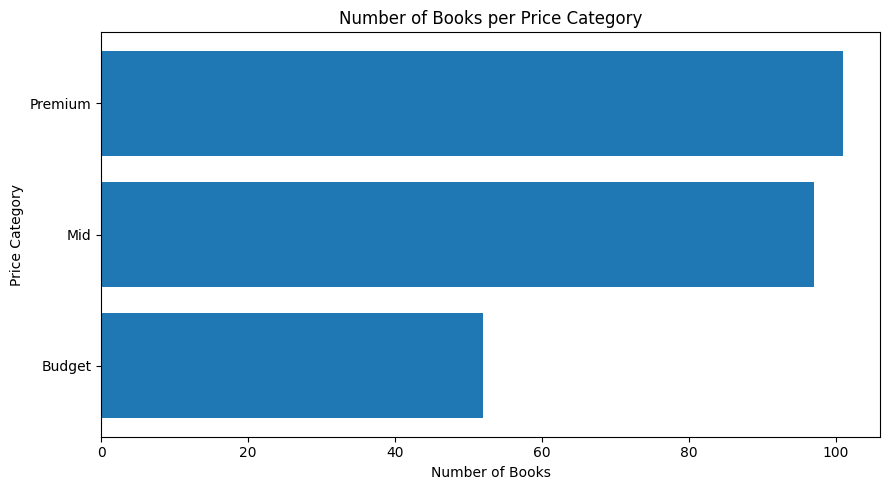

In [17]:

price_counts = (
    books_df["price_band"]
    .value_counts()
    .sort_values()
)

plt.figure(figsize=(9, 5))
plt.barh(price_counts.index.astype(str), price_counts.values)

plt.title("Number of Books per Price Category")
plt.xlabel("Number of Books")
plt.ylabel("Price Category")
plt.tight_layout()
plt.show()


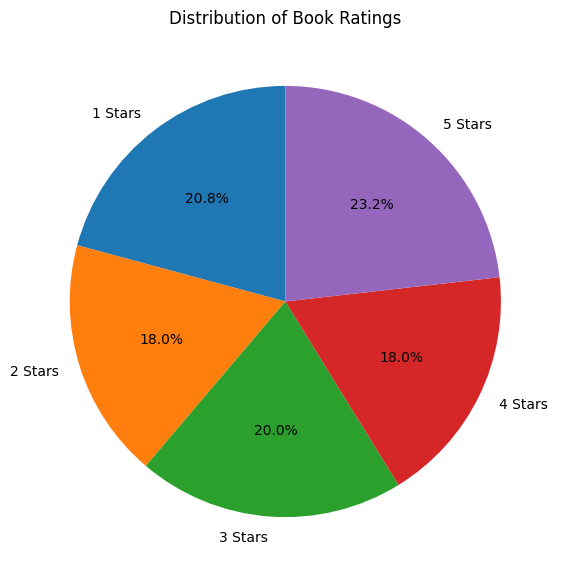

In [18]:

rating_counts = books_df["rating"].value_counts().sort_index()

plt.figure(figsize=(7, 7))
plt.pie(
    rating_counts.values,
    labels=[f"{int(r)} Stars" for r in rating_counts.index],
    autopct="%1.1f%%",
    startangle=90
)

plt.title("Distribution of Book Ratings")
plt.show()


In [19]:

import plotly.express as px

treemap_data = books_df.dropna(
    subset=["price_band", "rating_category"]
)

fig = px.treemap(
    treemap_data,
    path=["price_band", "rating_category"],
    title="Book Distribution: Price Category and Rating Category",
    color="price_band"
)

fig.show()


/usr/local/lib/python3.13/dist-packages/plotly/express/_core.py:1727: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  dfg = df.groupby(path[i:]).agg(agg_f)
/usr/local/lib/python3.13/dist-packages/plotly/express/_core.py:1727: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  dfg = df.groupby(path[i:]).agg(agg_f)


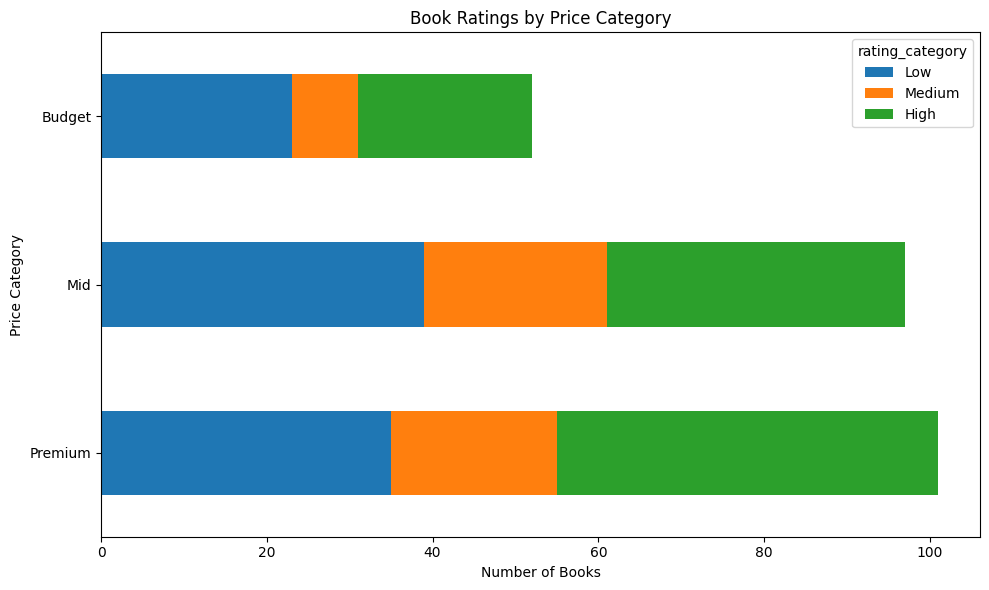

In [20]:

stacked = pd.crosstab(
    books_df["price_band"],
    books_df["rating_category"]
)

stacked = stacked.loc[
    stacked.sum(axis=1).sort_values(ascending=False).index
]

stacked.plot(
    kind="barh",
    stacked=True,
    figsize=(10, 6),
    title="Book Ratings by Price Category"
)

plt.xlabel("Number of Books")
plt.ylabel("Price Category")
plt.tight_layout()
plt.show()


In [21]:

sunburst_data = books_df.dropna(
    subset=["price_band", "rating_category"]
).copy()

fig = px.sunburst(
    sunburst_data,
    path=["price_band", "rating_category"],
    title="Book Hierarchy: Price Category to Rating Category"
)

fig.show()


/usr/local/lib/python3.13/dist-packages/plotly/express/_core.py:1727: FutureWarning:

The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.

/usr/local/lib/python3.13/dist-packages/plotly/express/_core.py:1727: FutureWarning:

The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.



In [22]:

import plotly.graph_objects as go

flow = pd.crosstab(
    books_df["price_band"],
    books_df["rating_category"]
).stack().reset_index(name="count")

flow = flow[flow["count"] > 0]

price_labels = sorted(flow["price_band"].astype(str).unique())
rating_labels = sorted(flow["rating_category"].astype(str).unique())

labels = price_labels + rating_labels
label_index = {label: i for i, label in enumerate(labels)}

source = [
    label_index[str(p)] for p in flow["price_band"]
]
target = [
    label_index[str(r)] for r in flow["rating_category"]
]

fig = go.Figure(data=[go.Sankey(
    node=dict(
        label=labels,
        pad=15,
        thickness=20
    ),
    link=dict(
        source=source,
        target=target,
        value=flow["count"].tolist()
    )
)])

fig.update_layout(
    title="Sankey Diagram: Price Category to Rating Category"
)

fig.show()


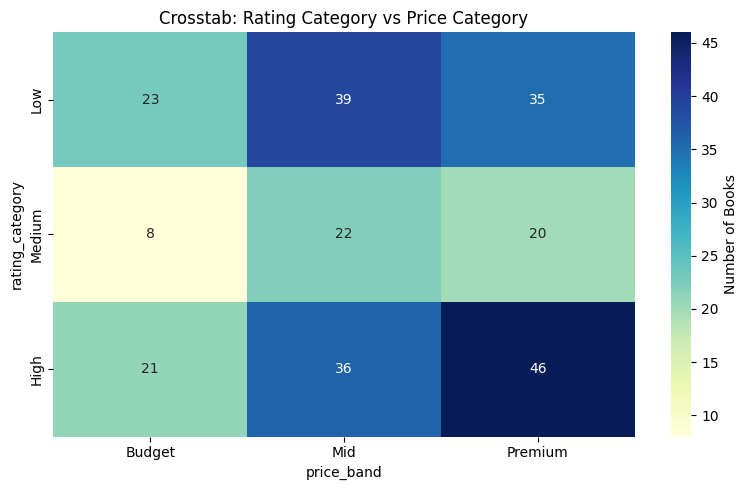

In [23]:

ct = pd.crosstab(
    books_df["rating_category"],
    books_df["price_band"]
)

plt.figure(figsize=(8, 5))

sns.heatmap(
    ct,
    annot=True,
    fmt="d",
    cmap="YlGnBu",
    cbar_kws={"label": "Number of Books"}
)

plt.title("Crosstab: Rating Category vs Price Category")
plt.tight_layout()
plt.show()


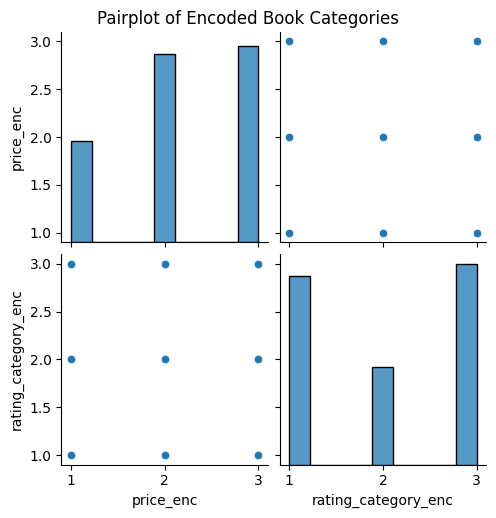

In [24]:

enc = books_df[["price_enc", "rating_category_enc"]].copy()

enc["price_enc"] = pd.to_numeric(
    enc["price_enc"], errors="coerce"
)
enc["rating_category_enc"] = pd.to_numeric(
    enc["rating_category_enc"], errors="coerce"
)

enc = enc.dropna()

sns.pairplot(
    enc,
    diag_kind="hist"
)

plt.suptitle(
    "Pairplot of Encoded Book Categories",
    y=1.02
)

plt.show()


In [25]:

books_df["price_enc"] = books_df["price_band"].map({
    "Budget": 1,
    "Mid": 2,
    "Premium": 3
}).astype(float)

books_df["rating_category_enc"] = books_df["rating_category"].map({
    "Low": 1,
    "Medium": 2,
    "High": 3
}).astype(float)


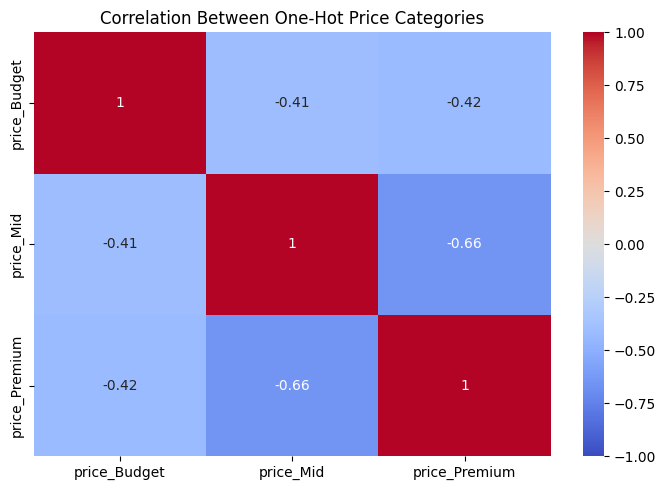

In [26]:

price_one_hot = pd.get_dummies(
    books_df["price_band"],
    prefix="price",
    dtype=int
)

corr = price_one_hot.corr()

plt.figure(figsize=(7, 5))

sns.heatmap(
    corr,
    annot=True,
    cmap="coolwarm",
    vmin=-1,
    vmax=1
)

plt.title("Correlation Between One-Hot Price Categories")
plt.tight_layout()
plt.show()


In [27]:

print("========== FINAL DATASET REPORT ==========")

print("Original dataset shape:", df.shape)
print("Cleaned dataset shape:", books_df.shape)
print("Feature-engineered dataset shape:", books_encoded.shape)

print("\nFinal dataset columns:")
print(books_encoded.columns.tolist())

print("\nMissing values:")
print(books_encoded.isnull().sum())

print("\nSummary statistics:")
display(books_df[["price", "rating"]].describe())

print("\nPrice category distribution:")
print(books_df["price_band"].value_counts())

print("\nRating category distribution:")
print(books_df["rating_category"].value_counts())


========== FINAL DATASET REPORT ==========
Original dataset shape: (50, 23)
Cleaned dataset shape: (250, 9)
Feature-engineered dataset shape: (250, 15)

Final dataset columns:
['price', 'rating', 'availability', 'book_link', 'price_band', 'rating_category', 'price_enc', 'rating_category_enc', 'availability_enc', 'price_Budget', 'price_Mid', 'price_Premium', 'rating_Low', 'rating_Medium', 'rating_High']

Missing values:
price                  0
rating                 0
availability           0
book_link              0
price_band             0
rating_category        0
price_enc              0
rating_category_enc    0
availability_enc       0
price_Budget           0
price_Mid              0
price_Premium          0
rating_Low             0
rating_Medium          0
rating_High            0
dtype: int64

Summary statistics:


,price,rating
count,250.000000,250.00000
mean,35.208400,3.04800
std,14.696633,1.45815
min,10.010000,1.00000
25%,23.135000,2.00000
50%,35.855000,3.00000
75%,48.052500,4.00000
max,59.950000,5.00000



Price category distribution:
price_band
Premium    101
Mid         97
Budget      52
Name: count, dtype: int64

Rating category distribution:
rating_category
High      103
Low        97
Medium     50
Name: count, dtype: int64


In [28]:

books_encoded.to_csv(
    "books_feature_engineered.csv",
    index=False
)

print("Final feature-engineered dataset saved!")


Final feature-engineered dataset saved!


In [29]:

from google.colab import files

files.download("books_feature_engineered.csv")


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>